# 5. Additional controls: partners, decisiveness and selection

Three questions raised in review:

1. **Is it the *learning partners*, or just the payoffs?** The bandit and the IPD differ in payoffs, states and
   non-stationarity, not only in whether the partner learns. I keep the IPD game exactly the same and swap the
   partners for ones that never learn:
   * **Random partner** (cooperates 40% of the time, whatever the agent does). The agent's choice can't affect the
     future, so this is a **payoff-matched bandit**: two "arms" paying like cooperating (R or S) and defecting (T or P).
   * **Tit-for-tat partner** (copies the agent's last move). Responsive, but its strategy never changes.
   * **Learning partners** (the original setup).
2. **Do the results need near-random agents?** With β = 10, agents choose almost at random (≈ 40–46% cooperation
   everywhere). I re-run with much more decisive agents (β = 30 and 100).
3. **Do the results need rank-based selection?** Rank-based selection lets a tiny payoff edge count as much as a
   large one. I re-run with **fitness-proportional** selection, where tiny edges give tiny advantages.

Two worlds throughout: **high temptation** (T = 5, noise 0.05) and **low temptation** (T = 3.5, noise 0.20).

**How to read the outcomes**
* If random and tit-for-tat partners give the same pattern as learning partners → the effect comes from the
  **payoff structure**, and "learning partners" is not needed to explain it.
* If only learning partners give the pattern → there is something specifically **multi-agent** about it.
* If the pattern disappears with decisive agents or proportional selection → the evolved biases depend on
  near-random choice or on amplification by selection, which must be stated as a limitation.

Runtime: about 30–40 minutes in Colab (10 runs per condition).

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

## Model code
The full contents of `evolution.py` (now including `ipd_fixed_partner` and the `selection_type` option).

In [2]:
"""
evolution.py -- Evolving learning biases (alpha+, alpha-) in populations
=========================================================================
Project: Does evolution favour optimistic learners in social dilemmas?

Each generation:
  1. Every agent lives one "lifetime" in an environment and learns with its
     own (alpha_pos, alpha_neg).  Fitness = mean reward obtained.
  2. Parents are sampled with probability increasing in fitness
     (rank-based selection, Wright-Fisher style).
  3. Offspring inherit their parent's (alpha_pos, alpha_neg) + Gaussian mutation.

Environments (same evolutionary loop):
  * bandit_lifetime            individual learning, myopic (gamma = 0)
                               -> conceptual replication of Hoxha, Sperber &
                                  Palminteri (2025, PNAS)
  * bandit_lifetime_farsighted individual learning, farsighted (gamma > 0) -- control
  * ipd_lifetime               multi-agent learning: agents learn against each other
                               in the Iterated Prisoner's Dilemma -- extension
  * ipd_fixed_partner          same game, but partners do NOT learn (memoryless random
                               cooperator, or tit-for-tat) -- isolates the role of
                               learning partners vs payoff structure
  * random_lifetime            fitness is pure noise -- neutral-drift control

Scaling conventions (applied in every environment, so conditions are comparable):
  * Payoffs lie in [0, 1].
  * Starting values  Q0 = 0.5 / (1 - gamma)   (neutral given the discount factor)
  * Softmax is applied to (1 - gamma) * Q      (same choice noise for any gamma)
Both can be overridden (q_init=..., rescale=False) to reproduce the original,
flawed settings discussed in the README.

Everything is vectorised over the population with NumPy.
"""

import inspect
import numpy as np


def softmax_choice(Q, beta, rng):
    """Vectorised softmax over the last axis. Q: (n, 2). Returns actions (n,)."""
    z = beta * (Q - Q.max(axis=1, keepdims=True))
    p1 = np.exp(z[:, 1]) / np.exp(z).sum(axis=1)
    return (rng.random(len(Q)) < p1).astype(int)


def asym_update(q, delta, a_pos, a_neg):
    """Asymmetric learning-rate update, vectorised."""
    lr = np.where(delta > 0, a_pos, a_neg)
    return q + lr * delta


def neutral_q(gamma):
    """Neutral starting value: midpoint payoff (0.5) summed over the discounted future."""
    return 0.5 / (1 - gamma)


# ------------------------------------------------------------------
# Lifetimes
# ------------------------------------------------------------------
def bandit_lifetime_farsighted(a_pos, a_neg, rng, probs=(0.25, 0.75), n_trials=100,
                               beta=10.0, gamma=0.9, q_init=None, rescale=True):
    """Each agent independently learns a 2-armed Bernoulli bandit.
    Arm positions are randomised per agent. Returns fitness (n,)."""
    n = len(a_pos)
    q_init = neutral_q(gamma) if q_init is None else q_init
    scale = (1 - gamma) if rescale else 1.0
    best = rng.integers(0, 2, n)                       # which arm is better
    p = np.where(best[:, None] == np.arange(2), probs[1], probs[0])  # (n, 2)
    Q = np.full((n, 2), float(q_init))
    total = np.zeros(n)
    idx = np.arange(n)
    for _ in range(n_trials):
        a = softmax_choice(Q * scale, beta, rng)
        r = (rng.random(n) < p[idx, a]).astype(float)
        delta = r + gamma * Q.max(axis=1) - Q[idx, a]
        Q[idx, a] = asym_update(Q[idx, a], delta, a_pos, a_neg)
        total += r
    return total / n_trials


def bandit_lifetime(a_pos, a_neg, rng, **kw):
    """Myopic bandit (gamma = 0): the standard individual-learning task."""
    kw.setdefault("gamma", 0.0)
    return bandit_lifetime_farsighted(a_pos, a_neg, rng, **kw)


def make_pd(temptation=5.0, reward=3.0, punishment=1.0, sucker=0.0, payoff_scale=None):
    """PD payoff matrix PD[my_action, their_action].
    By default divided by T (min-max scaling to [0, 1], since S = 0). With a fixed
    payoff_scale (e.g. 5.5 = the largest T used), the gaps between outcomes no
    longer change with T, so choice noise under a fixed beta is comparable across T."""
    scale = temptation if payoff_scale is None else payoff_scale
    return np.array([[reward, sucker],
                     [temptation, punishment]], dtype=float) / scale


def ipd_lifetime(a_pos, a_neg, rng, n_rounds=100, n_partners=4, noise=0.05,
                 beta=10.0, gamma=0.9, q_init=None, rescale=True,
                 temptation=5.0, payoff_scale=None, log=None):
    """Agents are randomly paired and play the iterated PD, learning online
    (state = partner's last move; 2 = first round). Repeated with
    n_partners random pairings; Q-values are reset for each new partner and the
    first round with each partner uses state 2 ("no history").
    Returns fitness (n,) = mean payoff per round.
    If log is a list, appends (realised cooperation, intended cooperation), where
    intended = the agent's choice before the trembling-hand flip."""
    n = len(a_pos)
    assert n % 2 == 0
    q_init = neutral_q(gamma) if q_init is None else q_init
    scale = (1 - gamma) if rescale else 1.0
    pd = make_pd(temptation, payoff_scale=payoff_scale)
    fitness = np.zeros(n)
    coop = coop_int = 0.0
    for _ in range(n_partners):
        perm = rng.permutation(n)
        i, j = perm[: n // 2], perm[n // 2:]            # pair i[k] with j[k]
        Q = np.full((n, 3, 2), float(q_init))           # fresh learning per partner
        s = np.full(n, 2)
        idx = np.arange(n)
        for _ in range(n_rounds):
            a = softmax_choice(Q[idx, s] * scale, beta, rng)
            coop_int += (a == 0).mean()
            flip = rng.random(n) < noise                # trembling hand
            a = np.where(flip, 1 - a, a)
            partner_a = np.empty(n, dtype=int)
            partner_a[i], partner_a[j] = a[j], a[i]
            r = pd[a, partner_a]
            coop += (a == 0).mean()
            s_next = partner_a                          # observe partner's move
            target = r + gamma * Q[idx, s_next].max(axis=1)
            delta = target - Q[idx, s, a]
            Q[idx, s, a] = asym_update(Q[idx, s, a], delta, a_pos, a_neg)
            s = s_next
            fitness += r
    if log is not None:                                 # optional: record cooperation
        log.append((coop / (n_rounds * n_partners), coop_int / (n_rounds * n_partners)))
    return fitness / (n_rounds * n_partners)


def ipd_fixed_partner(a_pos, a_neg, rng, partner="random", p_coop=0.4, n_rounds=100,
                      n_partners=4, noise=0.05, beta=10.0, gamma=0.9, q_init=None,
                      rescale=True, temptation=5.0, payoff_scale=None, log=None):
    """Control: identical game, payoffs, states, noise and learning rule as
    ipd_lifetime, but each agent plays a partner that does NOT learn.

    partner="random": cooperates with fixed probability p_coop every round,
        ignoring the agent. The agent's choice does not affect the future, so this
        is a bandit whose two arms pay like cooperating (R or S) and defecting
        (T or P): a "payoff-matched bandit".
    partner="tft": tit-for-tat. Cooperates in the first round, then copies the
        agent's last (realised) move. Responsive but fixed: the future depends on
        the agent's choice, but the partner never changes its strategy.
    The partner's moves are also subject to the trembling-hand noise."""
    n = len(a_pos)
    q_init = neutral_q(gamma) if q_init is None else q_init
    scale = (1 - gamma) if rescale else 1.0
    pd = make_pd(temptation, payoff_scale=payoff_scale)
    fitness = np.zeros(n)
    coop = coop_int = 0.0
    idx = np.arange(n)
    for _ in range(n_partners):
        Q = np.full((n, 3, 2), float(q_init))
        s = np.full(n, 2)
        last_a = np.zeros(n, dtype=int)                 # TFT cooperates first
        for t in range(n_rounds):
            a = softmax_choice(Q[idx, s] * scale, beta, rng)
            coop_int += (a == 0).mean()
            a = np.where(rng.random(n) < noise, 1 - a, a)
            if partner == "random":
                pa = (rng.random(n) >= p_coop).astype(int)   # 0 = C with prob p_coop
            elif partner == "tft":
                pa = last_a.copy() if t > 0 else np.zeros(n, dtype=int)
            else:
                raise ValueError(partner)
            pa = np.where(rng.random(n) < noise, 1 - pa, pa)
            r = pd[a, pa]
            coop += (a == 0).mean()
            target = r + gamma * Q[idx, pa].max(axis=1)
            delta = target - Q[idx, s, a]
            Q[idx, s, a] = asym_update(Q[idx, s, a], delta, a_pos, a_neg)
            s, last_a = pa, a
            fitness += r
    if log is not None:
        log.append((coop / (n_rounds * n_partners), coop_int / (n_rounds * n_partners)))
    return fitness / (n_rounds * n_partners)


def random_lifetime(a_pos, a_neg, rng, **_):
    """Control: fitness is pure noise, unrelated to (alpha+, alpha-).
    Shows what mutation + clipping + drift alone do to the optimism index."""
    return rng.random(len(a_pos))


# ------------------------------------------------------------------
# Evolutionary loop
# ------------------------------------------------------------------
def evolve(lifetime, n_agents=100, n_generations=150, mut_sd=0.03,
           selection=2.0, selection_type="rank", init="uniform", seed=0, **env_kwargs):
    """Run evolution. Returns dict of per-generation traces.

    selection_type="rank" (default): P(parent) ~ exp(selection * rank / (n - 1)).
        Only the ORDER of payoffs matters, so tiny payoff differences count as much
        as large ones.
    selection_type="proportional": P(parent) ~ payoff (Wright-Fisher). Tiny payoff
        differences now give only tiny reproductive advantages."""
    rng = np.random.default_rng(seed)
    if init == "uniform":
        a_pos = rng.uniform(0.05, 0.95, n_agents)
        a_neg = rng.uniform(0.05, 0.95, n_agents)
    else:                                               # start unbiased
        a_pos = np.full(n_agents, init)
        a_neg = np.full(n_agents, init)

    trace = {k: [] for k in ("a_pos", "a_neg", "bias", "fitness", "coop", "coop_intended")}
    for g in range(n_generations):
        log = []
        if "log" in inspect.signature(lifetime).parameters:
            fit = lifetime(a_pos, a_neg, rng, log=log, **env_kwargs)
        else:
            fit = lifetime(a_pos, a_neg, rng, **env_kwargs)
        trace["coop"].append(log[0][0] if log else np.nan)
        trace["coop_intended"].append(log[0][1] if log else np.nan)
        bias = (a_pos - a_neg) / (a_pos + a_neg)
        trace["a_pos"].append(a_pos.mean())
        trace["a_neg"].append(a_neg.mean())
        trace["bias"].append(bias.mean())
        trace["fitness"].append(fit.mean())

        if selection_type == "rank":
            ranks = fit.argsort().argsort() / (n_agents - 1)
            w = np.exp(selection * ranks)
        elif selection_type == "proportional":
            w = np.clip(fit, 1e-12, None)
        else:
            raise ValueError(selection_type)
        w = w / w.sum()
        parents = rng.choice(n_agents, size=n_agents, p=w)
        a_pos = np.clip(a_pos[parents] + rng.normal(0, mut_sd, n_agents), 0.01, 1.0)
        a_neg = np.clip(a_neg[parents] + rng.normal(0, mut_sd, n_agents), 0.01, 1.0)

    out = {k: np.array(v) for k, v in trace.items()}
    out["final_a_pos"], out["final_a_neg"] = a_pos, a_neg    # final population (for distributions)
    return out


def summarise(runs, last=30):
    """Mean and SE (across seeds) of the optimism index over the last generations,
    plus mean cooperation."""
    b = np.array([r["bias"][-last:].mean() for r in runs])
    def coop(key):
        if np.all(np.isnan(runs[0][key])):
            return np.nan
        return np.mean([r[key][-last:].mean() for r in runs])
    return dict(optimism=b.mean(), se=b.std(ddof=1) / np.sqrt(len(b)),
                cooperation=coop("coop"), cooperation_intended=coop("coop_intended"),
                a_pos=np.mean([r["a_pos"][-last:].mean() for r in runs]),
                a_neg=np.mean([r["a_neg"][-last:].mean() for r in runs]))


In [3]:
N_SEEDS, N_GEN, LAST = 10, 150, 30
WORLDS = {
    "High temptation (T = 5, noise 0.05)":  dict(temptation=5.0, noise=0.05),
    "Low temptation (T = 3.5, noise 0.20)": dict(temptation=3.5, noise=0.20),
}
rows = []
def run(analysis, world, label, fn, **kw):
    t0 = time.time()
    runs = [evolve(fn, n_generations=N_GEN, seed=s, **kw) for s in range(N_SEEDS)]
    s = summarise(runs, LAST)
    s["fitness"] = np.mean([r["fitness"][-LAST:].mean() for r in runs])
    rows.append(dict(analysis=analysis, world=world, condition=label, **s))
    print(f"[{analysis}] {world[:15]:<15} | {label:<26} optimism={s['optimism']:+.2f} (SE {s['se']:.2f})  "
          f"alpha+={s['a_pos']:.2f} alpha-={s['a_neg']:.2f}  coop={s['cooperation_intended']:.2f}  "
          f"[{time.time()-t0:.0f}s]")
    return s

## 1. Learning partners vs non-learning partners (~15 min)

In [4]:
PARTNERS = [
    ("Random partner (p = 0.4)", ipd_fixed_partner, dict(partner="random", p_coop=0.4)),
    ("Tit-for-tat partner",      ipd_fixed_partner, dict(partner="tft")),
    ("Learning partners",        ipd_lifetime,      dict()),
]
partner_res = {}
for world, wkw in WORLDS.items():
    for label, fn, pkw in PARTNERS:
        partner_res[(world, label)] = run("partners", world, label, fn, **wkw, **pkw)

[partners] High temptation | Random partner (p = 0.4)   optimism=+0.81 (SE 0.01)  alpha+=0.82 alpha-=0.09  coop=0.41  [78s]
[partners] High temptation | Tit-for-tat partner        optimism=-0.19 (SE 0.05)  alpha+=0.05 alpha-=0.10  coop=0.47  [75s]
[partners] High temptation | Learning partners          optimism=+0.80 (SE 0.02)  alpha+=0.82 alpha-=0.10  coop=0.41  [76s]
[partners] Low temptation  | Random partner (p = 0.4)   optimism=-0.19 (SE 0.06)  alpha+=0.50 alpha-=0.71  coop=0.44  [78s]
[partners] Low temptation  | Tit-for-tat partner        optimism=+0.25 (SE 0.07)  alpha+=0.41 alpha-=0.19  coop=0.46  [77s]
[partners] Low temptation  | Learning partners          optimism=-0.34 (SE 0.05)  alpha+=0.42 alpha-=0.79  coop=0.44  [73s]


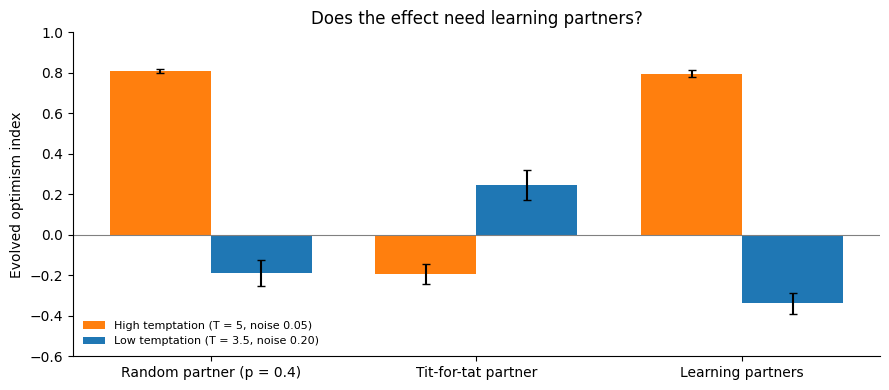

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
labels = [p[0] for p in PARTNERS]
x = np.arange(len(labels)); w = 0.38
for k, (world, c) in enumerate(zip(WORLDS, ["tab:orange", "tab:blue"])):
    vals = [partner_res[(world, l)]["optimism"] for l in labels]
    errs = [partner_res[(world, l)]["se"] for l in labels]
    ax.bar(x + (k - 0.5) * w, vals, w, yerr=errs, capsize=3, color=c, label=world)
ax.axhline(0, c="0.5", lw=0.8)
ax.set_xticks(x, labels); ax.set(ylabel="Evolved optimism index", ylim=(-0.6, 1),
                                  title="Does the effect need learning partners?")
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figures/05_partners.png", dpi=150); plt.show()

## 2. More decisive agents (~10 min)
β = 10 is the default. Higher β means agents pick their preferred action more reliably.

In [6]:
BETAS = [10.0, 30.0, 100.0]
beta_res = {}
for world, wkw in WORLDS.items():
    for b in BETAS:
        beta_res[(world, b)] = run("decisiveness", world, f"beta = {b:g}", ipd_lifetime, beta=b, **wkw)

[decisiveness] High temptation | beta = 10                  optimism=+0.80 (SE 0.02)  alpha+=0.82 alpha-=0.10  coop=0.41  [72s]
[decisiveness] High temptation | beta = 30                  optimism=+0.84 (SE 0.01)  alpha+=0.84 alpha-=0.08  coop=0.26  [73s]
[decisiveness] High temptation | beta = 100                 optimism=+0.79 (SE 0.01)  alpha+=0.79 alpha-=0.10  coop=0.23  [70s]
[decisiveness] Low temptation  | beta = 10                  optimism=-0.34 (SE 0.05)  alpha+=0.42 alpha-=0.79  coop=0.44  [72s]
[decisiveness] Low temptation  | beta = 30                  optimism=-0.07 (SE 0.03)  alpha+=0.69 alpha-=0.78  coop=0.36  [72s]
[decisiveness] Low temptation  | beta = 100                 optimism=-0.14 (SE 0.08)  alpha+=0.42 alpha-=0.59  coop=0.24  [73s]


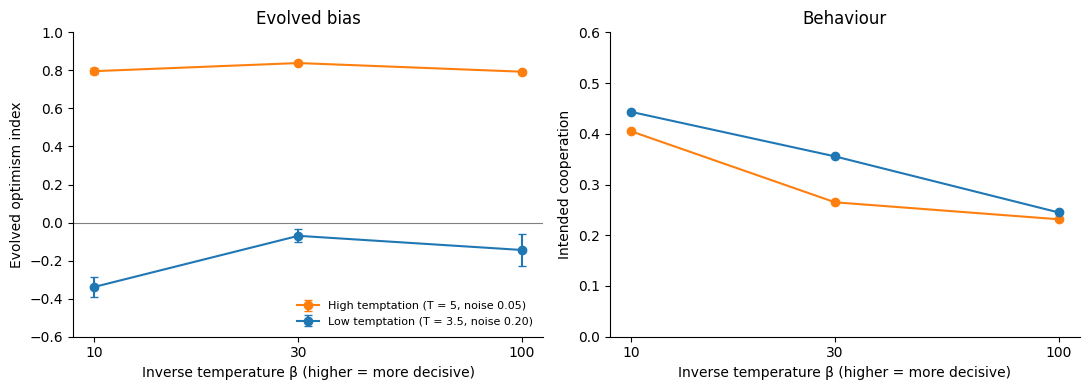

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for world, c in zip(WORLDS, ["tab:orange", "tab:blue"]):
    axes[0].errorbar(BETAS, [beta_res[(world, b)]["optimism"] for b in BETAS],
                     yerr=[beta_res[(world, b)]["se"] for b in BETAS], marker="o", capsize=3, color=c, label=world)
    axes[1].plot(BETAS, [beta_res[(world, b)]["cooperation_intended"] for b in BETAS], "o-", color=c, label=world)
for ax in axes:
    ax.set_xscale("log"); ax.minorticks_off(); ax.set_xticks(BETAS, [f"{b:g}" for b in BETAS])
    ax.set_xlabel("Inverse temperature β (higher = more decisive)"); ax.spines[["top", "right"]].set_visible(False)
axes[0].axhline(0, c="0.5", lw=0.8)
axes[0].set(ylabel="Evolved optimism index", ylim=(-0.6, 1), title="Evolved bias")
axes[1].set(ylabel="Intended cooperation", ylim=(0, 0.6), title="Behaviour")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig("figures/05_decisiveness.png", dpi=150); plt.show()

## 3. Fitness-proportional selection (~8 min)
Compared with the default rank-based selection and with neutral drift (random fitness) under the same rule.

[selection] High temptation | Fitness-proportional       optimism=+0.29 (SE 0.06)  alpha+=0.66 alpha-=0.39  coop=0.42  [72s]
[selection] Low temptation  | Fitness-proportional       optimism=-0.10 (SE 0.09)  alpha+=0.47 alpha-=0.57  coop=0.45  [71s]
[selection] Drift control   | Drift, proportional        optimism=+0.14 (SE 0.06)  alpha+=0.55 alpha-=0.43  coop=nan  [0s]


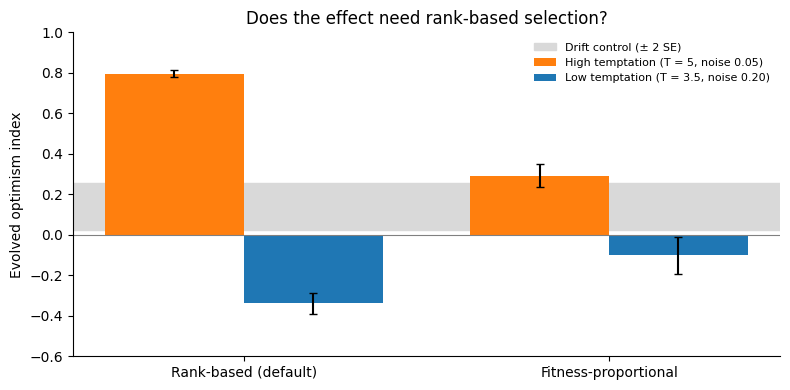

In [8]:
sel_res = {}
for world, wkw in WORLDS.items():
    sel_res[(world, "Rank-based (default)")] = partner_res[(world, "Learning partners")]
    sel_res[(world, "Fitness-proportional")] = run("selection", world, "Fitness-proportional",
                                                    ipd_lifetime, selection_type="proportional", **wkw)
drift_prop = run("selection", "Drift control", "Drift, proportional", random_lifetime,
                 selection_type="proportional")

pd.DataFrame(rows).to_csv("results/additional_controls.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
labels = ["Rank-based (default)", "Fitness-proportional"]
x = np.arange(len(labels)); w = 0.38
for k, (world, c) in enumerate(zip(WORLDS, ["tab:orange", "tab:blue"])):
    ax.bar(x + (k - 0.5) * w, [sel_res[(world, l)]["optimism"] for l in labels], w,
           yerr=[sel_res[(world, l)]["se"] for l in labels], capsize=3, color=c, label=world)
ax.axhspan(drift_prop["optimism"] - 2 * drift_prop["se"], drift_prop["optimism"] + 2 * drift_prop["se"],
           color="0.85", zorder=0, label="Drift control (± 2 SE)")
ax.axhline(0, c="0.5", lw=0.8)
ax.set_xticks(x, labels); ax.set(ylabel="Evolved optimism index", ylim=(-0.6, 1),
                                  title="Does the effect need rank-based selection?")
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figures/05_selection.png", dpi=150); plt.show()